# Nested-CV 模型结果分析

这个 notebook 读取 `nested_cv_balanced` 中已经完成的五个 outer folds，比较各折在独立测试来源上的指标，并检查 inner CV 选出的超参数。

这里仅做结果检查，不重新训练模型。需要生成正式 CSV 汇总时，运行 `results_analysis/summarize_nested_cv.py`。

In [7]:
from pathlib import Path
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 本地和服务器都使用根目录 project_config.py。
def find_project_root(start=None):
    path = Path(start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        config = candidate / 'project_config.py'
        if (candidate / 'workspace').exists() and config.exists():
            return candidate
    raise FileNotFoundError('Run this notebook from the project or flattened server working directory.')

PROJECT_ROOT = find_project_root()
CONFIG_DIR = PROJECT_ROOT
if str(CONFIG_DIR) not in sys.path:
    sys.path.insert(0, str(CONFIG_DIR))

from project_config import WORKSPACE_DIR

# 优先读取环境变量；未设置时使用当前平衡数据集的默认模型目录。
MODEL_ROOT = Path(os.environ.get('STORM_PETREL_MODEL_ROOT', WORKSPACE_DIR / 'models' / 'nested_cv_balanced')).expanduser().resolve()

METRICS = ['precision_0_5', 'recall_0_5', 'f1_0_5', 'auprc', 'auroc']
pd.set_option('display.max_columns', 50)
print(f'Model root: {MODEL_ROOT}')

Model root: /home/zenith/Projects/strom_petrels/workspace/models/nested_cv_balanced


## Outer-fold 测试指标

每个 outer fold 的测试集都由训练阶段从未见过的 `source_file` 组成。五折测试集合合起来覆盖全部 2000 个 clips，每个 clip 恰好测试一次。

指标含义：

- `precision_0_5`：预测为正类的样本中，真正正类所占比例；越高表示误报越少。
- `recall_0_5`：所有真正正类中被检出的比例；越高表示漏报越少。
- `f1_0_5`：precision 和 recall 的调和平均。
- `auprc`：所有阈值下 precision-recall 表现，适合比较正类检测能力。
- `auroc`：所有阈值下正负类排序能力。
- `mean`：五个 fold 指标的非加权平均，每折权重相同。
- `std`：fold 之间的标准差，用于观察模型对不同来源是否稳定。

> 注意：当前 TFLite 预测输出表现为 logits，而训练脚本生成的字段仍命名为 `*_0_5`。AUPRC/AUROC 不受单一阈值影响；固定阈值指标在正式报告前应先统一完成 sigmoid 概率转换。`f1_opt` 没有在这里作为主要指标展示，因为当前最优阈值是在 outer test 上搜索的，会产生乐观偏差。

In [8]:
# 每个 outer_XX/metrics.csv 对应一次独立 outer test 评估。
rows = []
for outer_dir in sorted(MODEL_ROOT.glob('outer_*')):
    path = outer_dir / 'metrics.csv'
    if path.is_file():
        row = pd.read_csv(path).iloc[0].to_dict()
        row['fold'] = outer_dir.name.removeprefix('outer_')
        rows.append(row)

metrics = pd.DataFrame(rows)
if metrics.empty:
    raise FileNotFoundError(f'No completed outer-fold metrics under {MODEL_ROOT}')

# 只保留适合跨 fold 比较的主要指标。
available = [name for name in METRICS if name in metrics.columns]
fold_metrics = metrics.set_index('fold')[available].apply(pd.to_numeric)
# mean/std 按 fold 计算，不会因为某个 fold 的测试样本更多就获得更高权重。
summary = pd.concat([fold_metrics, pd.DataFrame([fold_metrics.mean(), fold_metrics.std(ddof=1)], index=['mean', 'std'])])
display(summary)
print(f'Completed outer folds: {len(fold_metrics)}/5')

,precision_0_5,recall_0_5,f1_0_5,auprc,auroc
01,0.990950,1.000000,0.995455,1.000000,1.000000
02,1.000000,1.000000,1.000000,1.000000,1.000000
03,1.000000,0.983871,0.991870,1.000000,1.000000
04,0.995455,1.000000,0.997722,1.000000,1.000000
05,0.989848,0.994898,0.992366,0.999897,0.999896
mean,0.995250,0.995754,0.995483,0.999979,0.999979
std,0.004818,0.007000,0.003471,0.000046,0.000047


Completed outer folds: 5/5


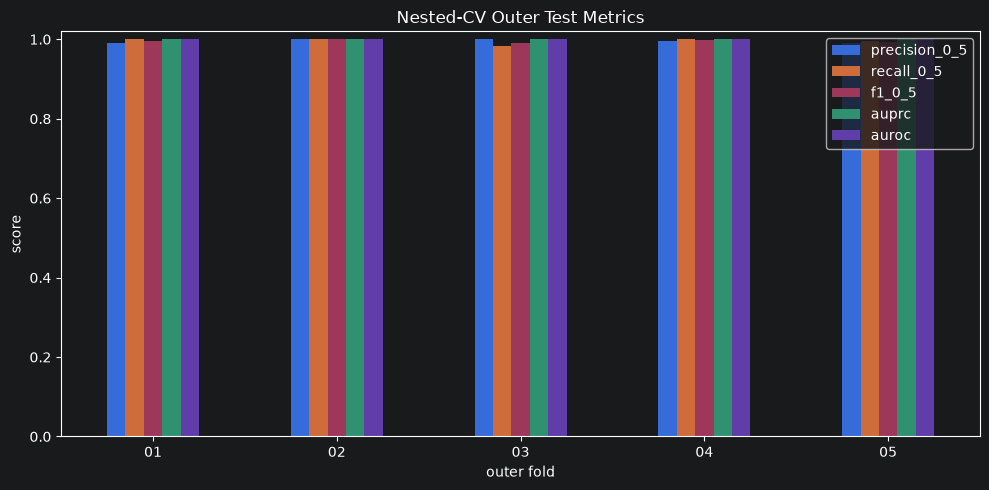

In [9]:
# 柱状图用于观察不同测试来源组合之间的性能波动。
ax = fold_metrics.plot(kind='bar', figsize=(10, 5))
ax.set_ylim(0, 1.02)
ax.set_title('Nested-CV Outer Test Metrics')
ax.set_ylabel('score')
ax.set_xlabel('outer fold')
plt.xticks(rotation=0)
plt.tight_layout()

## Inner CV 选中的超参数

每个 outer fold 只使用自己的 outer train 做三折 inner CV，并根据 inner validation 结果选择超参数。不同 outer folds 可以选出不同配置，这是 nested CV 的正常现象。

字段说明：

- `name`：预定义超参数组合名称。
- `learning_rate`：分类头学习率。
- `hidden_units`：额外隐藏层大小；0 表示线性分类头。
- `dropout`：训练时的 dropout 比例。
- `selected_by_folds`：该配置被多少个 outer folds 选中。

In [10]:
# 汇总每个 outer fold 最终采用的超参数。
selected_rows = []
for outer_dir in sorted(MODEL_ROOT.glob('outer_*')):
    path = outer_dir / 'selected_hyperparameters.csv'
    if path.is_file():
        selected_rows.append(pd.read_csv(path))
selected = pd.concat(selected_rows, ignore_index=True) if selected_rows else pd.DataFrame()
display(selected)
if not selected.empty:
    display(selected.groupby('name').size().rename('selected_by_folds').to_frame())

,name,learning_rate,hidden_units,dropout,outer_fold
0,baseline,0.00010,0,0.0,1
1,hidden256_dropout03,0.00010,256,0.3,2
2,hidden256_dropout03,0.00010,256,0.3,3
3,hidden256_dropout02,0.00005,256,0.2,4
4,hidden256_dropout03,0.00010,256,0.3,5


,selected_by_folds
name,
baseline,1
hidden256_dropout02,1
hidden256_dropout03,3
